In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/merged.csv")
df["HourDK"] = pd.to_datetime(df["HourDK"], utc=True).dt.tz_convert("Europe/Copenhagen")
df.head(10)

,HourUTC,area,price_eur_mwh,carbon_g_kwh,wind_mwh,solar_mwh,consumption_mwh,wind_share,HourDK
0,2024-01-01 00:00:00,DK1,28.139999,200.750000,2353.300984,0.190397,2600.621879,0.904899,2024-01-01 01:00:00+01:00
1,2024-01-01 01:00:00,DK1,26.660000,197.750000,2234.114528,0.219881,2765.984289,0.807710,2024-01-01 02:00:00+01:00
2,2024-01-01 02:00:00,DK1,4.140000,204.916667,2201.163530,0.223736,2952.482372,0.745530,2024-01-01 03:00:00+01:00
3,2024-01-01 03:00:00,DK1,-0.030000,197.000000,1728.339193,0.186471,2940.747997,0.587721,2024-01-01 04:00:00+01:00
4,2024-01-01 04:00:00,DK1,-0.020000,224.000000,1722.579211,0.252871,2958.059300,0.582334,2024-01-01 05:00:00+01:00
5,2024-01-01 05:00:00,DK1,-0.050000,219.416667,1741.203001,0.234003,2943.865063,0.591468,2024-01-01 06:00:00+01:00
6,2024-01-01 06:00:00,DK1,-0.020000,203.916667,1843.878795,0.245452,2924.453283,0.630504,2024-01-01 07:00:00+01:00
7,2024-01-01 07:00:00,DK1,0.000000,222.666667,1774.277561,0.268744,2879.306016,0.616217,2024-01-01 08:00:00+01:00
8,2024-01-01 08:00:00,DK1,0.080000,208.583333,2193.738268,8.044223,2930.110629,0.748688,2024-01-01 09:00:00+01:00
9,2024-01-01 09:00:00,DK1,41.340000,208.000000,2131.916885,26.027960,2835.562151,0.751850,2024-01-01 10:00:00+01:00


In [2]:
df.describe()

,price_eur_mwh,carbon_g_kwh,wind_mwh,solar_mwh,consumption_mwh,wind_share
count,17566.000000,17566.000000,17566.000000,17566.000000,17566.000000,17566.000000
mean,70.750010,88.657928,1170.592699,214.990185,2186.928850,0.493702
std,51.196667,52.686259,1136.449991,392.983866,700.115365,0.386274
min,-60.049999,9.000000,0.019418,0.043393,968.054060,0.000011
25%,39.340000,51.500000,297.734057,0.266496,1634.088730,0.156561
50%,68.269997,72.416667,823.062655,6.224463,2031.126592,0.424378
75%,95.615002,114.416667,1545.325001,262.641545,2787.188126,0.755914
max,936.309998,337.583333,4905.629931,2306.786410,4228.427907,2.070415


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17566 entries, 0 to 17565
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype                            
---  ------           --------------  -----                            
 0   HourUTC          17566 non-null  object                           
 1   area             17566 non-null  object                           
 2   price_eur_mwh    17566 non-null  float64                          
 3   carbon_g_kwh     17566 non-null  float64                          
 4   wind_mwh         17566 non-null  float64                          
 5   solar_mwh        17566 non-null  float64                          
 6   consumption_mwh  17566 non-null  float64                          
 7   wind_share       17566 non-null  float64                          
 8   HourDK           17566 non-null  datetime64[ns, Europe/Copenhagen]
dtypes: datetime64[ns, Europe/Copenhagen](1), float64(6), object(2)
memory usage: 1.2+ MB


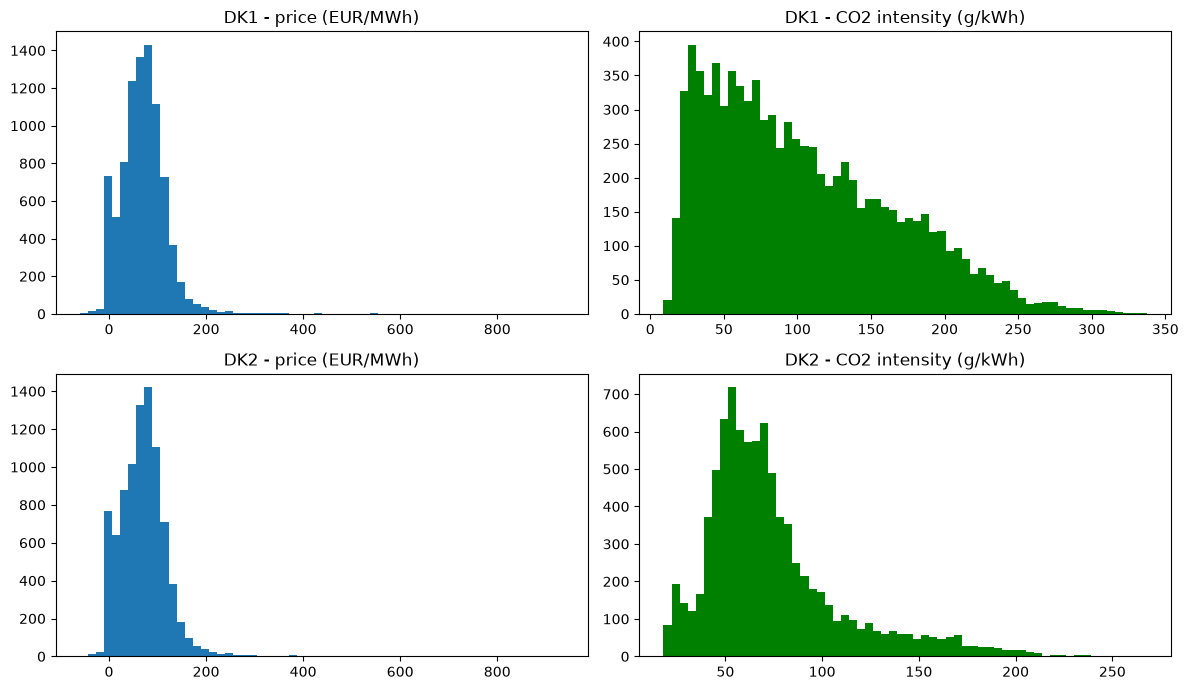

Hours with negative prices:
area
DK1    375
DK2    275
dtype: int64

Negative-price hours by month:
area     DK1   DK2
HourDK            
1       10.0   NaN
3       10.0   NaN
4       32.0  28.0
5       75.0  59.0
6       57.0  44.0
7       74.0  59.0
8       68.0  55.0
9       26.0  11.0
10      13.0  13.0
11       6.0   6.0
12       4.0   NaN


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, area in enumerate(["DK1", "DK2"]):
    d = df[df["area"] == area]
    axes[i, 0].hist(d["price_eur_mwh"], bins=60)
    axes[i, 0].set_title(f"{area} - price (EUR/MWh)")
    axes[i, 1].hist(d["carbon_g_kwh"], bins=60, color="green")
    axes[i, 1].set_title(f"{area} - CO2 intensity (g/kWh)")
plt.tight_layout()
plt.show()

neg = df[df["price_eur_mwh"] < 0]
print("Hours with negative prices:")
print(neg.groupby("area").size())
print("\nNegative-price hours by month:")
print(neg.groupby([neg["HourDK"].dt.month, "area"]).size().unstack())

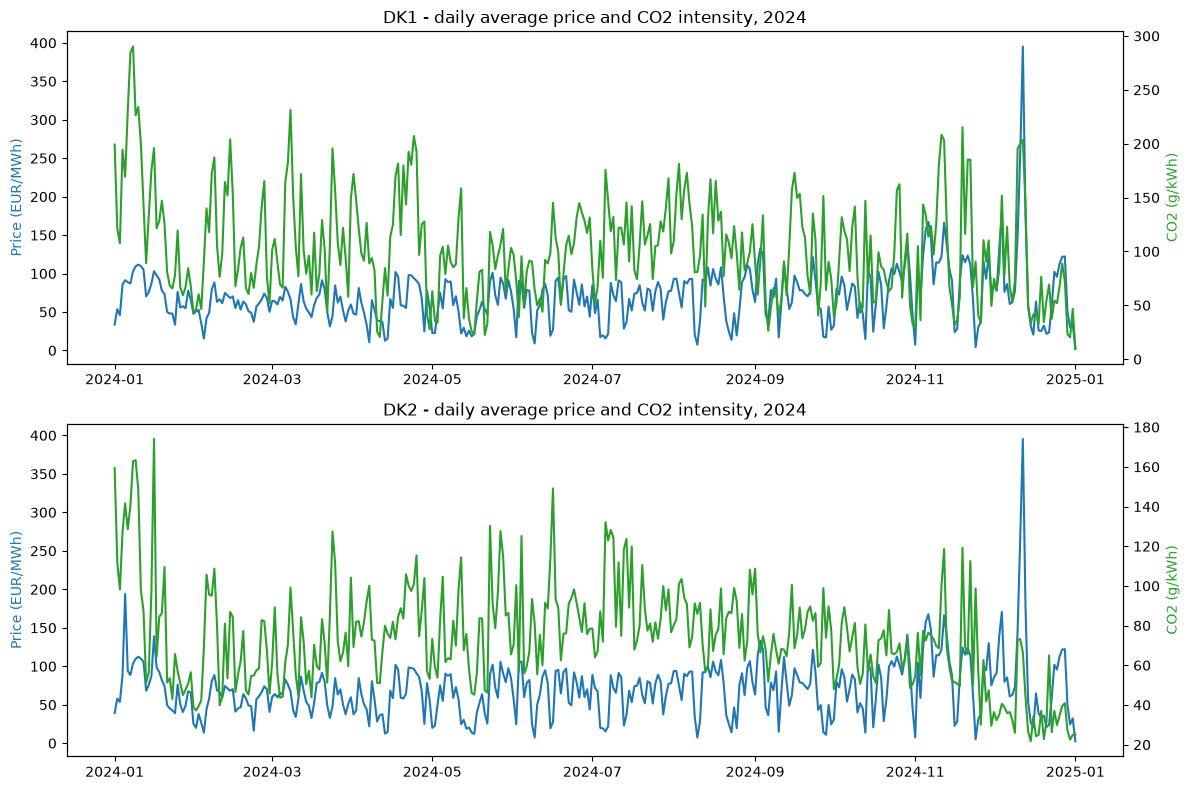

In [5]:
df["date"] = df["HourDK"].dt.date
daily = df.groupby(["area", "date"])[["price_eur_mwh", "carbon_g_kwh"]].mean().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for i, area in enumerate(["DK1", "DK2"]):
    d = daily[daily["area"] == area]
    ax1 = axes[i]
    ax1.plot(d["date"], d["price_eur_mwh"], color="tab:blue")
    ax1.set_ylabel("Price (EUR/MWh)", color="tab:blue")
    ax2 = ax1.twinx()
    ax2.plot(d["date"], d["carbon_g_kwh"], color="tab:green")
    ax2.set_ylabel("CO2 (g/kWh)", color="tab:green")
    ax1.set_title(f"{area} - daily average price and CO2 intensity, 2024")
plt.tight_layout()
plt.show()

In [6]:
cols = ["HourDK", "area", "price_eur_mwh", "carbon_g_kwh"]
top = df.sort_values("price_eur_mwh", ascending=False).groupby("area").head(10)
print("10 most expensive hours per area:")
print(top[cols].sort_values(["area", "price_eur_mwh"], ascending=[True, False]))

df["carbon_pct"] = df.groupby("area")["carbon_g_kwh"].rank(pct=True) * 100
top = df.sort_values("price_eur_mwh", ascending=False).groupby("area").head(100)
print("\nCO2 percentile of the 100 most expensive hours (50 = average, 100 = dirtiest):")
print(top.groupby("area")["carbon_pct"].mean().round(0))

10 most expensive hours per area:
                         HourDK area  price_eur_mwh  carbon_g_kwh
8319  2024-12-12 17:00:00+01:00  DK1     936.280029    207.333333
8318  2024-12-12 16:00:00+01:00  DK1     818.979980    203.416667
8320  2024-12-12 18:00:00+01:00  DK1     674.179993    219.250000
8317  2024-12-12 15:00:00+01:00  DK1     668.489990    206.083333
8310  2024-12-12 08:00:00+01:00  DK1     655.599976    200.333333
8311  2024-12-12 09:00:00+01:00  DK1     646.760010    192.500000
8309  2024-12-12 07:00:00+01:00  DK1     599.989990    212.833333
8321  2024-12-12 19:00:00+01:00  DK1     551.010010    226.750000
7455  2024-11-06 17:00:00+01:00  DK1     550.000000    118.333333
8312  2024-12-12 10:00:00+01:00  DK1     543.830017    190.750000
17102 2024-12-12 17:00:00+01:00  DK2     936.309998    116.916667
17101 2024-12-12 16:00:00+01:00  DK2     819.010010     58.583333
17103 2024-12-12 18:00:00+01:00  DK2     674.200012     74.916667
17100 2024-12-12 15:00:00+01:00  DK2     6

In [7]:
# How often do DK1 and DK2 have the same price?
p = df.pivot_table(index="HourUTC", columns="area", values="price_eur_mwh")
same = (p["DK1"] - p["DK2"]).abs() < 0.5
print(f"Hours with (almost) the same price: {same.mean():.0%}")

Hours with (almost) the same price: 74%


In [8]:
# At what time of day do negative prices happen?
neg = df[df["price_eur_mwh"] < 0]
print(neg.groupby([neg["HourDK"].dt.hour, "area"]).size().unstack())

area     DK1   DK2
HourDK            
0        4.0   3.0
1        7.0   5.0
2        6.0   5.0
3        9.0   5.0
4        9.0   6.0
5        8.0   5.0
6        5.0   3.0
7        3.0   2.0
8        4.0   4.0
9        8.0   8.0
10      19.0  16.0
11      31.0  23.0
12      45.0  36.0
13      52.0  44.0
14      64.0  44.0
15      49.0  35.0
16      33.0  24.0
17      18.0   7.0
18       1.0   NaN


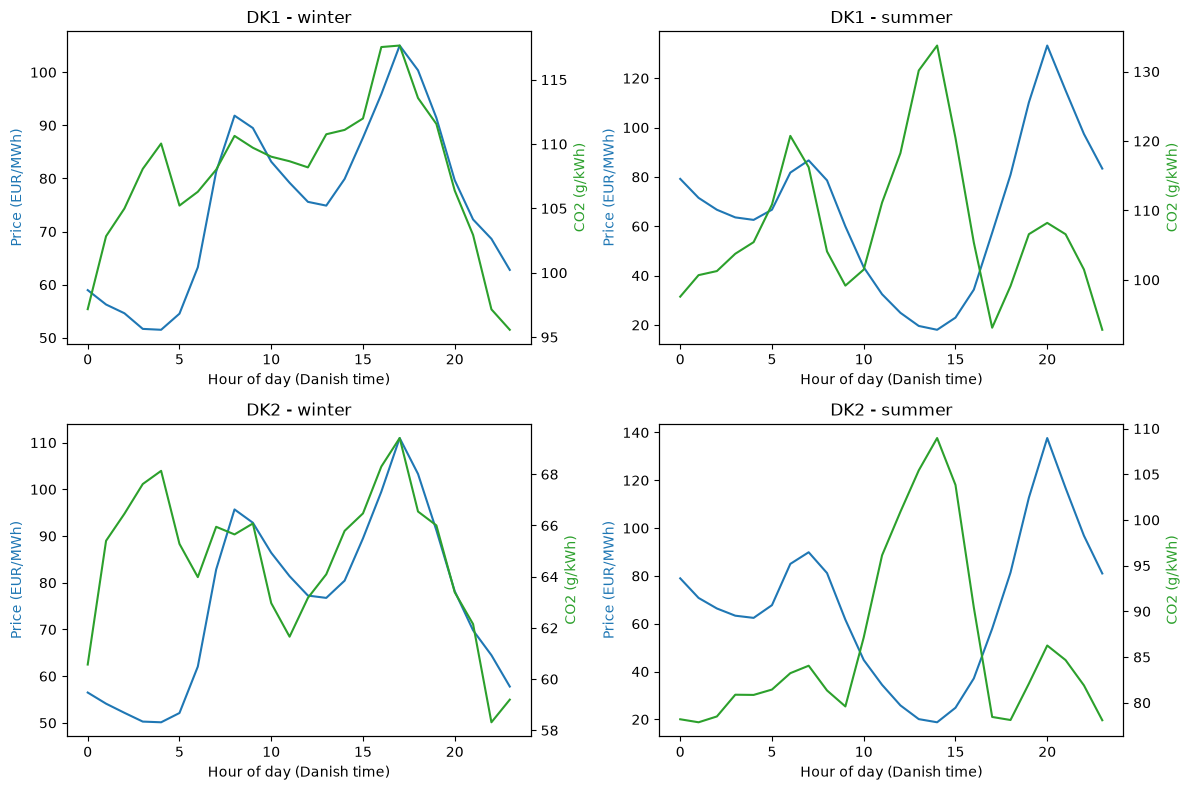

Cheapest and cleanest hour on average:
DK1 summer: cheapest 14:00, cleanest 23:00
DK1 winter: cheapest 4:00, cleanest 23:00
DK2 summer: cheapest 14:00, cleanest 1:00
DK2 winter: cheapest 4:00, cleanest 22:00


In [9]:
df["hour"] = df["HourDK"].dt.hour
df["month"] = df["HourDK"].dt.month
df["season"] = "other"
df.loc[df["month"].isin([12, 1, 2]), "season"] = "winter"
df.loc[df["month"].isin([6, 7, 8]), "season"] = "summer"

prof = (df[df["season"] != "other"]
        .groupby(["area", "season", "hour"])[["price_eur_mwh", "carbon_g_kwh"]]
        .mean().reset_index())

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, area in enumerate(["DK1", "DK2"]):
    for j, season in enumerate(["winter", "summer"]):
        d = prof[(prof["area"] == area) & (prof["season"] == season)]
        ax1 = axes[i, j]
        ax1.plot(d["hour"], d["price_eur_mwh"], color="tab:blue")
        ax1.set_ylabel("Price (EUR/MWh)", color="tab:blue")
        ax2 = ax1.twinx()
        ax2.plot(d["hour"], d["carbon_g_kwh"], color="tab:green")
        ax2.set_ylabel("CO2 (g/kWh)", color="tab:green")
        ax1.set_title(f"{area} - {season}")
        ax1.set_xlabel("Hour of day (Danish time)")
plt.tight_layout()
plt.show()

print("Cheapest and cleanest hour on average:")
for (area, season), d in prof.groupby(["area", "season"]):
    cheap = d.loc[d["price_eur_mwh"].idxmin(), "hour"]
    clean = d.loc[d["carbon_g_kwh"].idxmin(), "hour"]
    print(f"{area} {season}: cheapest {cheap}:00, cleanest {clean}:00")

In [10]:
summer = df[df["season"] == "summer"]
print(summer.groupby(["area", "hour"])[["wind_mwh", "solar_mwh", "consumption_mwh"]]
      .mean().round(0).unstack("area"))

     wind_mwh        solar_mwh        consumption_mwh        
area      DK1    DK2       DK1    DK2             DK1     DK2
hour                                                         
0      1369.0  426.0       0.0    0.0          1980.0  1188.0
1      1349.0  409.0       0.0    0.0          1947.0  1153.0
2      1324.0  400.0       0.0    0.0          1927.0  1120.0
3      1297.0  376.0       0.0    0.0          1901.0  1090.0
4      1277.0  371.0       1.0    1.0          1883.0  1065.0
5      1278.0  370.0      25.0   12.0          1921.0  1089.0
6      1256.0  372.0     114.0   50.0          2090.0  1204.0
7      1258.0  369.0     315.0  132.0          2344.0  1373.0
8      1256.0  362.0     610.0  250.0          2544.0  1512.0
9      1284.0  347.0     879.0  364.0          2665.0  1612.0
10     1259.0  332.0    1099.0  456.0          2823.0  1678.0
11     1231.0  323.0    1226.0  515.0          2920.0  1706.0
12     1228.0  315.0    1280.0  552.0          2982.0  1722.0
13     1

area    DK1   DK2
month            
1      0.55  0.44
2      0.42  0.35
3      0.12  0.00
4      0.26 -0.01
5      0.13  0.10
6     -0.01 -0.16
7     -0.07 -0.18
8      0.20 -0.18
9      0.10 -0.20
10     0.29  0.15
11     0.57  0.32
12     0.65  0.46


/var/folders/4p/kk24d_ts03z6qmxrfh9hyn2c0000gn/T/ipykernel_6961/2030857980.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  corr = df.groupby(["month", "area"]).apply(


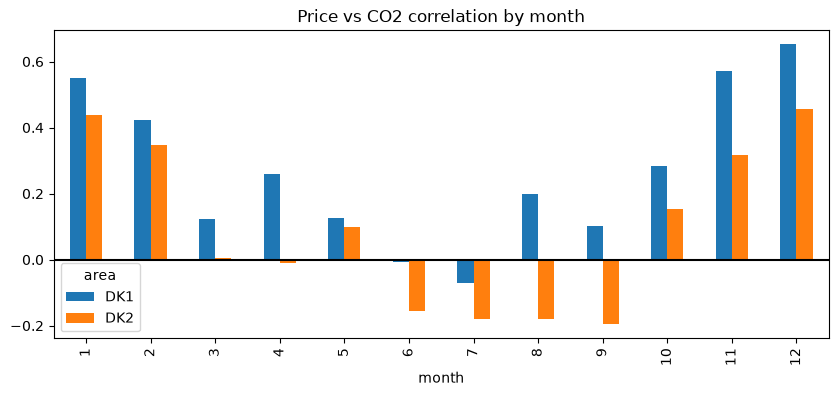

In [11]:
corr = df.groupby(["month", "area"]).apply(
    lambda d: d["price_eur_mwh"].corr(d["carbon_g_kwh"])).unstack()
print(corr.round(2))
corr.plot(kind="bar", figsize=(10, 4), title="Price vs CO2 correlation by month")
plt.axhline(0, color="black")
plt.show()

In [12]:
raw = pd.read_csv("data/ProductionConsumptionSettlement_2024-01-01_2025-01-01.csv")
raw["HourDK"] = pd.to_datetime(raw["HourUTC"], utc=True).dt.tz_convert("Europe/Copenhagen")
summer = raw[raw["HourDK"].dt.month.isin([6, 7, 8])].copy() # summer
summer["hour"] = summer["HourDK"].dt.hour

summer["period"] = None
summer.loc[summer["hour"].isin([0, 1, 2, 3, 4]), "period"] = "night"
summer.loc[summer["hour"].isin([12, 13, 14, 15]), "period"] = "midday"
summer = summer[summer["period"].notna()]

thermal = [c for c in raw.columns if "Power" in c and "Wind" not in c and "Solar" not in c]
exch = [c for c in raw.columns if "Exchange" in c]
print("Thermal columns:", thermal)
print("Exchange columns:", exch)

print(summer.groupby(["PriceArea", "period"])[thermal + exch].mean().T.round(0))

Thermal columns: ['CentralPowerMWh', 'LocalPowerMWh', 'CommercialPowerMWh', 'LocalPowerSelfConMWh', 'HydroPowerMWh', 'PowerToHeatMWh']
Exchange columns: ['ExchangeNO_MWh', 'ExchangeSE_MWh', 'ExchangeGE_MWh', 'ExchangeNL_MWh', 'ExchangeGB_MWh', 'ExchangeGreatBelt_MWh']
PriceArea                DK1            DK2        
period                midday   night midday   night
CentralPowerMWh        174.0   194.0   71.0   128.0
LocalPowerMWh           82.0    98.0   25.0    29.0
CommercialPowerMWh      55.0    63.0   72.0    75.0
LocalPowerSelfConMWh   120.0    39.0   43.0     4.0
HydroPowerMWh            2.0     2.0    0.0     0.0
PowerToHeatMWh         358.0    87.0   43.0    25.0
ExchangeNO_MWh         226.0  1324.0    NaN     NaN
ExchangeSE_MWh          66.0   471.0  395.0  1044.0
ExchangeGE_MWh         337.0 -1373.0  105.0  -622.0
ExchangeNL_MWh         160.0  -151.0    NaN     NaN
ExchangeGB_MWh        -642.0     9.0    NaN     NaN
ExchangeGreatBelt_MWh -121.0   -72.0  117.0    68.0


In [13]:
raw = pd.read_csv("data/ProductionConsumptionSettlement_2024-01-01_2025-01-01.csv")
raw["HourDK"] = pd.to_datetime(raw["HourUTC"], utc=True).dt.tz_convert("Europe/Copenhagen")
summer = raw[raw["HourDK"].dt.month.isin([12, 1, 2])].copy() # winter
summer["hour"] = summer["HourDK"].dt.hour

summer["period"] = None
summer.loc[summer["hour"].isin([0, 1, 2, 3, 4]), "period"] = "night"
summer.loc[summer["hour"].isin([12, 13, 14, 15]), "period"] = "midday"
summer = summer[summer["period"].notna()]

thermal = [c for c in raw.columns if "Power" in c and "Wind" not in c and "Solar" not in c]
exch = [c for c in raw.columns if "Exchange" in c]
print("Thermal columns:", thermal)
print("Exchange columns:", exch)

print(summer.groupby(["PriceArea", "period"])[thermal + exch].mean().T.round(0))

Thermal columns: ['CentralPowerMWh', 'LocalPowerMWh', 'CommercialPowerMWh', 'LocalPowerSelfConMWh', 'HydroPowerMWh', 'PowerToHeatMWh']
Exchange columns: ['ExchangeNO_MWh', 'ExchangeSE_MWh', 'ExchangeGE_MWh', 'ExchangeNL_MWh', 'ExchangeGB_MWh', 'ExchangeGreatBelt_MWh']
PriceArea                DK1           DK2       
period                midday  night midday  night
CentralPowerMWh        599.0  456.0  465.0  373.0
LocalPowerMWh          284.0  182.0   82.0   61.0
CommercialPowerMWh      72.0   66.0  186.0  152.0
LocalPowerSelfConMWh    47.0   33.0   19.0   14.0
HydroPowerMWh            4.0    4.0    0.0    0.0
PowerToHeatMWh         301.0  481.0   42.0   64.0
ExchangeNO_MWh         409.0   40.0    NaN    NaN
ExchangeSE_MWh         147.0  165.0  581.0  566.0
ExchangeGE_MWh         -14.0    8.0 -256.0 -310.0
ExchangeNL_MWh        -146.0 -110.0    NaN    NaN
ExchangeGB_MWh        -642.0 -460.0    NaN    NaN
ExchangeGreatBelt_MWh  -30.0   80.0   24.0  -86.0


# Cheap vs. clean: when should Danes shift their electricity use?

## 1. Data
All data from Energinet's Energi Data Service (free, public), calendar year 2024, price areas DK1 (West) and DK2 (East).

| Dataset | Content | Resolution |
|---|---|---|
| Elspotprices | Day-ahead price (EUR/MWh) | Hourly |
| ProductionConsumptionSettlement | Production by source, consumption, cross-border exchange (MWh) | Hourly |
| CO2Emis | CO2 intensity of consumed electricity (g/kWh), includes imports | 5-minute, averaged to hourly |

- Period: 2024 chosen because it is fully hourly (day-ahead prices moved to 15-minute resolution in Oct 2025).
- Electricity Maps historical data is not available on the free tier, so Energinet's CO2Emis is used instead.
- Final dataset: `data/merged.csv`, 8,783 of 8,784 hours per area, no missing values.

## 2. Method
- Downloaded via API in UTC (avoids daylight-saving duplicates), cached with the period in the file name.
- Summed wind and solar columns, computed wind share = wind / consumption.
- Averaged 5-minute CO2 to hourly, merged everything on hour + area.
- Used Danish local time (`HourDK`) for all hour-of-day and seasonal analysis.

## 3. Findings

**3.1 Price and CO2 are weakly related over the year**
- Correlation price vs CO2: DK1 = 0.26, DK2 = 0.04.

**3.2 DK1 and DK2 usually share one price, but not one CO2 level**
- 74% of hours have (almost) the same price in both areas.
- CO2 differs a lot: DK1 ranges 20 to 330 g/kWh, DK2 is concentrated around 50 to 70.
- So DK2's price mostly reflects the wider market, not its own grid. This explains its near-zero correlation.

**3.3 Negative prices are a summer midday effect**
- 375 negative-price hours in DK1, 275 in DK2, mostly April to August.
- Peak at 12:00 to 15:00 (solar), with a smaller night-time cluster (wind, low demand).

**3.4 Price spikes: 12 Dec 2024 (Dunkelflaute)**
- Highest price of the year: 936 EUR/MWh at 17:00 in both areas (low wind and sun across Northern Europe; verify and cite a source).
- Same price, different carbon: DK1 around 200 to 225 g/kWh, DK2 around 60 to 120.
- The 100 most expensive hours sit at the 79th CO2 percentile in DK1 and the 62nd in DK2.

**3.5 Seasonal flip: aligned in winter, opposite in summer**
- Winter: price and CO2 both peak around 17:00 and fall at night. Cheap = clean.
- Summer: at 14:00 price is lowest and CO2 is highest. The cheapest hour is the dirtiest.
- Cheapest vs cleanest hour on average:
  - DK1 summer: cheapest 14:00, cleanest 23:00
  - DK1 winter: cheapest 4:00, cleanest 23:00
  - DK2 summer: cheapest 14:00, cleanest 1:00
  - DK2 winter: cheapest 4:00, cleanest 22:00
- Monthly correlation: strongly positive Nov to Jan (DK1 up to 0.65), near zero or negative in summer. DK2 is negative every month from June to September (around -0.18). In DK1 the summer flip is weaker (August still +0.20).
- Note: CO2 swings are moderate (e.g. DK2 summer 78 to 109 g/kWh). Always state actual ranges, not just the shape.

**3.6 Why CO2 rises at summer midday: imports**
- Domestic renewable share is higher at midday (DK1: 83% at 13:00 vs 69% at midnight), so wind curtailment is not the cause.
- Domestic thermal falls at midday (DK2 central plants 128 to 71 MWh).
- The import mix changes (summer averages, positive = import):

| | DK1 night | DK1 midday | DK2 night | DK2 midday |
|---|---|---|---|---|
| Norway | 1,324 | 226 | - | - |
| Sweden | 471 | 66 | 1,044 | 395 |
| Germany | -1,373 | 337 | -622 | 105 |
| Netherlands | -151 | 160 | - | - |

- At night Denmark imports clean Nordic hydro and passes power on to Germany. At midday, cheap German and Dutch solar pushes Nordic imports out, Norway holds its hydro back, and Denmark imports from Germany and the Netherlands, whose mix is more carbon-intensive.
- Side details: electric boilers (PowerToHeat) use 4x more power at midday (358 vs 87 MWh in DK1); DK1 exports about 640 MWh to Great Britain at midday.
- Winter check (Dec to Feb): no import switch. Norway sends more at midday (DK1: 409 vs 40 MWh at night), Germany stays near zero. The switch to German imports is summer-specific.
- Winter midday CO2 is also higher than night, but because domestic thermal rises (DK1 central plants 599 vs 456 MWh) along with demand and price. Price and CO2 move together, so there is no conflict.
- Norwegian hydro flows to Denmark when Danish prices are high: summer nights, winter middays.

## 4. Caveats
- CO2Emis is a real-time estimate; Energinet states errors are generally not corrected.
- CHP emissions split with the 125% method; other methods give different numbers.
- Average intensity, not marginal. Shifting load changes marginal emissions, which can differ.
- Exchange sign convention (positive = import) to be confirmed in Energinet's documentation.
- Check how CO2Emis assigns emissions to imports, since finding 3.6 depends on it.
- Natural extension: compare with Electricity Maps' flow-traced intensity.

## 5. Next steps
- [ ] Daily window metric: % of days where the cheapest 4-hour window is also the cleanest
- [ ] EV simulation (10 kWh, 18:00 to 07:00): charge on plug-in vs cheapest vs cleanest; EUR/year, kg CO2/year, EUR per tonne avoided vs EU ETS price
- [ ] Pick 3 to 4 charts for the write-up (candidates: hour-of-day profiles, monthly correlation, import table)
- [ ] Write-up (2 pages) + README, send to Tobias